In [1]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, ClassicalRegister
from qiskit_aer import AerSimulator

def simulate_bb84_with_eve(bit_num):
    rng = np.random.default_rng()
    backend = AerSimulator()
    
    # 1. SETUP
    qc = QuantumCircuit(bit_num)
    cr_bob = ClassicalRegister(bit_num, name="bob")
    cr_eve = ClassicalRegister(bit_num, name="eve")
    qc.add_register(cr_bob, cr_eve)

    # Alice genera bit e basi
    abits = rng.integers(0, 2, size=bit_num) 
    abase = rng.integers(0, 2, size=bit_num) 

    # 2. PREPARAZIONE ALICE
    for n in range(bit_num):
        if abits[n] == 1: qc.x(n)
        if abase[n] == 1: qc.h(n)

    # 3. INTERCETTAZIONE EVE
    ebase = rng.integers(0, 2, size=bit_num) 
    for e in range(bit_num):
        if ebase[e] == 1: qc.h(e)
        qc.measure(e, cr_eve[e]) 
        if ebase[e] == 1: qc.h(e) 

    # 4. RICEZIONE BOB
    bbase = rng.integers(0, 2, size=bit_num) 
    for m in range(bit_num):
        if bbase[m] == 1: qc.h(m)
        qc.measure(m, cr_bob[m])

    # 5. ESECUZIONE E SIFTING
    job = backend.run(qc, shots=1, memory=True)
    result_str = job.result().get_memory()[0]
    raw_bits = result_str.split()
    bob_measurements = [int(b) for b in raw_bits[1][::-1]]

    # Sifting
    match_count = 0
    sifted_len = 0
    for i in range(bit_num):
        if abase[i] == bbase[i]:
            sifted_len += 1
            if abits[i] == bob_measurements[i]:
                match_count += 1
    
    qber = 1 - (match_count / sifted_len) if sifted_len > 0 else 0
    return qber

In [2]:
test_sizes = [20, 100, 1000]
iterations = 10
results = {}

print("Inizio simulazioni...")
for size in test_sizes:
    qbers = [simulate_bb84_with_eve(size) for _ in range(iterations)]
    results[size] = qbers
    print(f"Completato test per {size} bit.")

# Calcolo medie e deviazioni standard
means = [np.mean(results[s]) for s in test_sizes]
stds = [np.std(results[s]) for s in test_sizes]

print("\n--- RISULTATI ---")
for i, size in enumerate(test_sizes):
    print(f"Taglia {size:4} bit | QBER Medio: {means[i]:.2%} | Dev. Std: {stds[i]:.4f}")

Inizio simulazioni...
Completato test per 20 bit.
Completato test per 100 bit.
Completato test per 1000 bit.

--- RISULTATI ---
Taglia   20 bit | QBER Medio: 21.40% | Dev. Std: 0.0838
Taglia  100 bit | QBER Medio: 22.08% | Dev. Std: 0.0776
Taglia 1000 bit | QBER Medio: 25.14% | Dev. Std: 0.0169


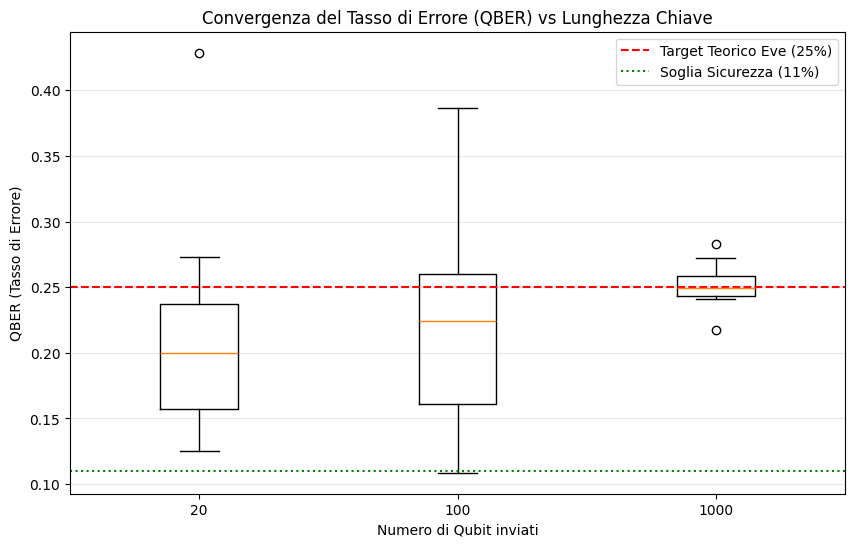

In [3]:
plt.figure(figsize=(10, 6))

# Creiamo un boxplot per vedere la dispersione
plt.boxplot([results[s] for s in test_sizes], tick_labels=[str(s) for s in test_sizes])

# Aggiungiamo la linea teorica del 25% e la soglia dell'11%
plt.axhline(y=0.25, color='r', linestyle='--', label='Target Teorico Eve (25%)')
plt.axhline(y=0.11, color='g', linestyle=':', label='Soglia Sicurezza (11%)')

plt.title("Convergenza del Tasso di Errore (QBER) vs Lunghezza Chiave")
plt.xlabel("Numero di Qubit inviati")
plt.ylabel("QBER (Tasso di Errore)")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()